In [1]:
import numpy as np
import pandas as pd
import re
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS

from sklearn.dummy import DummyClassifier

from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import StratifiedKFold, cross_validate, cross_val_predict, GridSearchCV
from sklearn.pipeline import make_pipeline
from sklearn.metrics import precision_score, recall_score, f1_score, fbeta_score, accuracy_score, ConfusionMatrixDisplay, make_scorer, classification_report
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix
import joblib
from claimlens.data import load_raw_data, FirstMessage, CleanText
from sentence_transformers import SentenceTransformer
from sklearn.preprocessing import FunctionTransformer


/Users/finn/code/MUlbing/ClaimLens/.venv/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
W1016 15:30:39.297000 69985 torch/distributed/elastic/multiprocessing/redirects.py:35] NOTE: Redirects are currently not supported in MacOs.


In [2]:
raw_data = load_raw_data("../raw_data/abcd_v1.1.json")

df = FirstMessage().build_df(raw_data)

df.head()

,split,id,flow,subflow,first_msgs,refund_intent,refund_output,n_words
0,train,3592,product_defect,return_size,"I need to return an item, can you help me with...",1,0,12
1,train,9489,product_defect,refund_status,just wanted to check on the status of a refund,0,0,10
2,train,3695,storewide_query,timing_4,I have got a promo code and I want to know whe...,0,0,27
3,train,5798,shipping_issue,manage,I would like to change my shipping deatails as...,1,0,17
4,train,3647,storewide_query,pricing_3,I have a really cool party coming up. And I ne...,0,0,36


In [3]:
cleaner = CleanText()

df['clean_text'] = df['first_msgs'].apply(cleaner.clean)
print("empty after cleaning:", (df["clean_text"] == "").sum())

empty after cleaning: 0


In [4]:
display(df[["first_msgs", "clean_text"]].head(10))

,first_msgs,clean_text
0,"I need to return an item, can you help me with...",need return item help
1,just wanted to check on the status of a refund,want check status refund
2,I have got a promo code and I want to know whe...,get promo code want know expire like use buy h...
3,I would like to change my shipping deatails as...,like change ship deatails change recently move
4,I have a really cool party coming up. And I ne...,cool party come need new clothe soon possible ...
5,I want an extension for my shopping service. I...,want extension shop service need time get money
6,I am trying to check the status of my order bu...,try check status order forget username cannot ...
7,I am trying to buy a pair of boots but they ar...,try buy pair boot not get add cart
8,I accidently ordered the wrong item and was wo...,accidently order wrong item wonder change item
9,I would like to confirm my address is correct ...,like confirm address correct order able


In [5]:
df

,split,id,flow,subflow,first_msgs,refund_intent,refund_output,n_words,clean_text
0,train,3592,product_defect,return_size,"I need to return an item, can you help me with...",1,0,12,need return item help
1,train,9489,product_defect,refund_status,just wanted to check on the status of a refund,0,0,10,want check status refund
2,train,3695,storewide_query,timing_4,I have got a promo code and I want to know whe...,0,0,27,get promo code want know expire like use buy h...
3,train,5798,shipping_issue,manage,I would like to change my shipping deatails as...,1,0,17,like change ship deatails change recently move
4,train,3647,storewide_query,pricing_3,I have a really cool party coming up. And I ne...,0,0,36,cool party come need new clothe soon possible ...
...,...,...,...,...,...,...,...,...,...
10037,test,1622,order_issue,manage_upgrade,I want to upgrade an order I have with you to ...,0,0,13,want upgrade order overnight ship
10038,test,3293,manage_account,status_credit_missing,I think I am missing a $40 credit from a subsc...,0,0,12,think miss credit subscription refund
10039,test,8492,subscription_inquiry,manage_extension,I would like an extension on my subscription.,0,0,8,like extension subscription
10040,test,189,storewide_query,pricing_1,How much do you charge to gift wrap items?,0,0,9,charge gift wrap item


In [6]:
# REFUND_SUBFLOWS = {
#     "refund_initiate",
#     "return_size",
#     "return_color",
#     "return_stain",
#     "manage_dispute_bill",
#     "bad_price_competitor",
#     "status_mystery_fee",
#     "refund_update",
#     "manage_cancel",
# }

# df["refund_request"] = df["subflow"].isin(REFUND_SUBFLOWS).astype(int)
# print(df["refund_request"].value_counts())

In [7]:
TARGET = "refund_intent"
train = df[df["split"] == "train"]
val = df[df["split"] == "dev"]
test = df[df["split"] == "test"]

X_train = train["clean_text"]
y_train = train[TARGET]

X_val = val["clean_text"]
y_val = val[TARGET]

X_test = test["clean_text"]
y_test = test[TARGET]

train_dev = df[df["split"].isin(["train", "dev"])]
X_td = train_dev["clean_text"]
y_td = train_dev[TARGET]

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

In [8]:
print(y_train.value_counts(normalize=True))

dummy = DummyClassifier(strategy="most_frequent")
dummy.fit(X_train, y_train)
y_pred = dummy.predict(X_val)

print("accuracy:", accuracy_score(y_val, y_pred))
print("precision:", precision_score(y_val, y_pred, zero_division=0))
print("recall:", recall_score(y_val, y_pred))

refund_intent
0    0.776948
1    0.223052
Name: proportion, dtype: float64
accuracy: 0.7719123505976095
precision: 0.0
recall: 0.0


In [9]:

embedding_model = SentenceTransformer('sentence-transformers/all-mpnet-base-v2')

def embed_texts(texts):
    texts_list = list(texts)
    return embedding_model.encode(texts_list, show_progress_bar=False)

embedding_transformer = FunctionTransformer(
    embed_texts,
    validate=False
)



models = {
    "count + none": make_pipeline(
        CountVectorizer(),
        LogisticRegression(max_iter=1000),
    ),
    "count + none + ngrams": make_pipeline(
        CountVectorizer(ngram_range=(1, 2)),
        LogisticRegression(max_iter=1000),
    ),
    "count + balanced": make_pipeline(
        CountVectorizer(),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
    "tfidf + none": make_pipeline(
        TfidfVectorizer(),
        LogisticRegression(max_iter=1000),
    ),
    "tfidf + balanced": make_pipeline(
        TfidfVectorizer(),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
    "tfidf + balanced + ngrams": make_pipeline(
        TfidfVectorizer(ngram_range=(1, 2)),
        LogisticRegression(max_iter=1000, class_weight="balanced"),
    ),
    "sentence-transformer + balanced": make_pipeline(
        embedding_transformer,
        LogisticRegression(max_iter=1000, class_weight="balanced", random_state=42)
    ),
}

Loading weights: 100%|██████████| 199/199 [00:00<00:00, 8592.76it/s]


In [10]:
def plot_confusion(y_true, y_pred, title):
    """Confusion matrix with plain-language labels, counts and row percentages."""
    # Counts and row percentages (each row adds up to 100%)
    cm = confusion_matrix(y_true, y_pred)
    cm_pct = confusion_matrix(y_true, y_pred, normalize="true")

    # Unpack the four cells: correct no, false alarm, missed, correct yes
    tn, fp, fn, tp = cm.ravel()
    tn_pct, fp_pct, fn_pct, tp_pct = cm_pct.ravel()

    # Text inside each cell, in the same layout as the grid
    labels = [
        [f"Correct: no refund intent\n{tn} ({tn_pct:.0%})", f"False alarm\n{fp} ({fp_pct:.0%})"],
        [f"Missed refund intent\n{fn} ({fn_pct:.0%})", f"Correct: refund intent\n{tp} ({tp_pct:.0%})"],
    ]

    plt.figure(figsize=(7, 5))
    sns.heatmap(
        cm_pct,
        annot=labels,
        fmt="",
        cmap="Blues",
        vmin=0,
        vmax=1,
        cbar=False,
        xticklabels=["Predicted: no refund", "Predicted: refund"],
        yticklabels=["Actually: no refund", "Actually: refund"],
    )
    plt.title(title)
    plt.show()

In [11]:
f2_scorer = make_scorer(fbeta_score, beta=2)

cv_results = []

for name, model in models.items():
    scores = cross_validate(
        model, X_td, y_td, cv=cv,
        scoring={"precision": "precision",
                 "recall": "recall",
                 "f2": f2_scorer}
    )
    cv_results.append({
        "model": name,
        "precision": scores["test_precision"].mean(),
        "recall": scores["test_recall"].mean(),
        "f2": scores["test_f2"].mean(),
        "f2_std": scores["test_f2"].std(),
    })
cv_results_df = pd.DataFrame(cv_results).sort_values("f2", ascending=False)
cv_best_name = cv_results_df.iloc[0]["model"]
print("Best model (CV):", cv_best_name)


cv_results_df

Best model (CV): tfidf + balanced + ngrams


,model,precision,recall,f2,f2_std
5,tfidf + balanced + ngrams,0.840279,0.912915,0.897290,0.007919
4,tfidf + balanced,0.780801,0.905982,0.877686,0.004122
2,count + balanced,0.800276,0.897081,0.875794,0.006356
1,count + none + ngrams,0.940266,0.844633,0.861973,0.017962
6,sentence-transformer + balanced,0.717052,0.900054,0.856227,0.011375
0,count + none,0.902725,0.813463,0.829780,0.011972
3,tfidf + none,0.910349,0.764971,0.790130,0.010765


In [12]:
best_pipe = models[cv_best_name]
pre_trained_model = models['sentence-transformer + balanced']

param_grid = {
    "tfidfvectorizer__ngram_range": [(1, 1), (1, 2), (1,3)],
    "tfidfvectorizer__min_df": [1, 2],
    "tfidfvectorizer__sublinear_tf": [True, False],


    "logisticregression__C": [0.1, 1.0, 10.0, 100],
    "logisticregression__class_weight": [None, "balanced"],
}

grid_search = GridSearchCV(
    estimator=best_pipe,
    param_grid=param_grid,
    cv=cv,
    scoring=f2_scorer,
    n_jobs=-1,
    verbose=1,
    refit=True
)
grid_search.fit(X_td, y_td)

Fitting 5 folds for each of 96 candidates, totalling 480 fits


,"estimator estimator: estimator objectThis is assumed to implement the scikit-learn estimator interface.Either estimator needs to provide a ``score`` function,or ``scoring`` must be passed.",Pipeline(step..._iter=1000))])
,"param_grid param_grid: dict or list of dictionariesDictionary with parameters names (`str`) as keys and lists ofparameter settings to try as values, or a list of suchdictionaries, in which case the grids spanned by each dictionaryin the list are explored. This enables searching over any sequenceof parameter settings.","{'logisticregression__C': [0.1, 1.0, ...], 'logisticregression__class_weight': [None, 'balanced'], 'tfidfvectorizer__min_df': [1, 2], 'tfidfvectorizer__ngram_range': [(1, ...), (1, ...), ...], ...}"
,"scoring scoring: str, callable, list, tuple or dict, default=NoneStrategy to evaluate the performance of the cross-validated model onthe test set.If `scoring` represents a single score, one can use:- a single string (see :ref:`scoring_string_names`);- a callable (see :ref:`scoring_callable`) that returns a single value;- `None`, the `estimator`'s :ref:`default evaluation criterion <scoring_api_overview>` is used.If `scoring` represents multiple scores, one can use:- a list or tuple of unique strings;- a callable returning a dictionary where the keys are the metric names and the values are the metric scores;- a dictionary with metric names as keys and callables as values.See :ref:`multimetric_grid_search` for an example.","make_scorer(f...dict', beta=2)"
,"n_jobs n_jobs: int, default=NoneNumber of jobs to run in parallel.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details... versionchanged:: v0.20 `n_jobs` default changed from 1 to None",-1
,"cv cv: int, cross-validation generator or an iterable, default=NoneDetermines the cross-validation splitting strategy.Possible inputs for cv are:- None, to use the default 5-fold cross validation,- integer, to specify the number of folds in a `(Stratified)KFold`,- :term:`CV splitter`,- an iterable yielding (train, test) splits as arrays of indices.For integer/None inputs, if the estimator is a classifier and ``y`` iseither binary or multiclass, :class:`StratifiedKFold` is used. In allother cases, :class:`KFold` is used. These splitters are instantiatedwith `shuffle=False` so the splits will be the same across calls.Refer :ref:`User Guide <cross_validation>` for the variouscross-validation strategies that can be used here... versionchanged:: 0.22 ``cv`` default value if None changed from 3-fold to 5-fold.",StratifiedKFo... shuffle=True)
,"verbose verbose: int, default=0Controls the verbosity of information printed during fitting, with highervalues yielding more detailed logging.- 0 : no messages are printed;- >=1 : summary of the total number of fits;- >=2 : computation time for each fold and parameter candidate;- >=3 : fold indices and scores;- >=10 : parameter candidate indices and START messages before each fit.",1
,"refit refit: bool, str, or callable, default=TrueRefit an estimator using the best found parameters on the wholedataset.For multiple metric evaluation, this needs to be a `str` denoting thescorer that would be used to find the best parameters for refittingthe estimator at the end.Where there are considerations other than maximum score inchoosing a best estimator, ``refit`` can be set to a function whichreturns the selected ``best_index_`` given ``cv_results_``. In thatcase, the ``best_estimator_`` and ``best_params_`` will be setaccording to the returned ``best_index_`` while the ``best_score_``attribute will not be available.The refitted estimator is made available at the ``best_estimator_``attribute and permits using ``predict`` directly on this``GridSearchCV`` instance.Also for multiple metric evaluation, the attributes ``best_index_``,``best_score_`` and ``best_params_`` will only be available if``refit`` is set and all of them will be determi

In [13]:
pre_trained_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('functiontransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function emb...t 0x167ad2e80>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True
,"feature_names_out feature_names_out: callable, 'one-to-one' or None, default=NoneDetermines the list of feature names that will be returned by the`get_feature_names_out` method. If it is 'one-to-one', then the outputfeature names will be equal to the input feature names. If it is acallable, then it must take two positional arguments: this`FunctionTransformer` (`self`) and an array-like of input feature names(`input_features`). It must return an array-like of output featurenames. The `get_feature_names_out` method is only defined if`feature_names_out` is not None.See ``get_feature_names_out`` for more details... versionadded:: 1.1",None
,"kw_args kw_args: dict, def

In [14]:
print(f"Best accuracy score:{grid_search.best_score_:.4f}")
print("Best parameters configuration:")
for param, value in grid_search.best_params_.items():
    print(f"  {param}: {value}")

Best accuracy score:0.9059
Best parameters configuration:
  logisticregression__C: 10.0
  logisticregression__class_weight: balanced
  tfidfvectorizer__min_df: 1
  tfidfvectorizer__ngram_range: (1, 3)
  tfidfvectorizer__sublinear_tf: False


In [15]:
grid_search_model = grid_search.best_estimator_

td_probs = cross_val_predict(
    grid_search_model, X_td, y_td, cv=cv, method="predict_proba"
)[:, 1]

threshold_results = []

for threshold in [0.35, 0.40, 0.42, 0.44, 0.46, 0.48, 0.50, 0.55]:
    y_pred = (td_probs >= threshold).astype(int)

    threshold_results.append({
        "threshold": threshold,
        "precision": precision_score(y_td, y_pred),
        "recall": recall_score(y_td, y_pred),
        "f2": fbeta_score(y_td, y_pred, beta=2),
    })

threshold_df = pd.DataFrame(threshold_results)
threshold_df

,threshold,precision,recall,f2
0,0.35,0.792100,0.942603,0.908094
1,0.40,0.815166,0.936170,0.909178
2,0.42,0.823427,0.932212,0.908214
3,0.44,0.831635,0.928748,0.907552
4,0.46,0.837209,0.926274,0.906977
5,0.48,0.844203,0.922316,0.905558
6,0.50,0.853927,0.919842,0.905857
7,0.55,0.869483,0.906482,0.898832


precision: 0.8432203389830508
recall: 0.908675799086758
f2: 0.8947841726618705


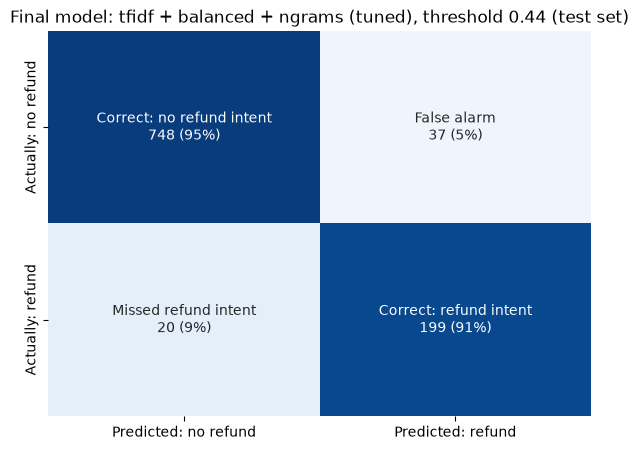

In [16]:
FINAL_THRESHOLD = 0.44
final_model = grid_search.best_estimator_

test_probs = final_model.predict_proba(X_test)[:, 1]
y_pred_test = (test_probs >= FINAL_THRESHOLD).astype(int)

print("precision:", precision_score(y_test, y_pred_test))
print("recall:", recall_score(y_test, y_pred_test))
print("f2:", fbeta_score(y_test, y_pred_test, beta=2))

plot_confusion(
    y_test,
    y_pred_test,
    f"Final model: {cv_best_name} (tuned), threshold {FINAL_THRESHOLD} (test set)",
)

In [17]:
final_model

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidfvectorizer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"ngram_range ngram_range: tuple (min_n, max_n), default=(1, 1)The lower and upper boundary of the range of n-values for differentn-grams to be extracted. All values of n such that min_n <= n <= max_nwill be used. For example an ``ngram_range`` of ``(1, 1)`` means onlyunigrams, ``(1, 2)`` means unigrams and bigrams, and ``(2, 2)`` meansonly bigrams.Only applies if ``analyzer`` is not callable.","(1, ...)"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None


In [18]:
joblib.dump(final_model, "../models/tfidf_balanced_ngrams.joblib")
joblib.dump(FINAL_THRESHOLD, "../models/tfidf_balanced_ngrams_threshold.joblib")

['../models/tfidf_balanced_ngrams_threshold.joblib']

In [19]:
prompt = 'I want my money back'
cleaned_prompt = cleaner.clean(prompt)
print(cleaned_prompt)
refund_prob = final_model.predict_proba([cleaned_prompt])[0][1]
print(f"Refund request: {refund_prob:.0%}")

want money back
Refund request: 10%


In [20]:
pre_trained_model.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('functiontransformer', ...), ('logisticregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[int64](2,)","[0,1]"
,"func func: callable, default=NoneThe callable to use for the transformation. This will be passedthe same arguments as transform, with args and kwargs forwarded.If func is None, then func will be the identity function.",<function emb...t 0x167ad2e80>
,"inverse_func inverse_func: callable, default=NoneThe callable to use for the inverse transformation. This will bepassed the same arguments as inverse transform, with args andkwargs forwarded. If inverse_func is None, then inverse_funcwill be the identity function.",None
,"validate validate: bool, default=FalseIndicate that the input X array should be checked before calling``func``. The possibilities are:- If False, there is no input validation.- If True, then X will be converted to a 2-dimensional NumPy array or sparse matrix. If the conversion is not possible an exception is raised... versionchanged:: 0.22 The default of ``validate`` changed from True to False.",False
,"accept_sparse accept_sparse: bool, default=FalseIndicate that func accepts a sparse matrix as input. If validate isFalse, this has no effect. Otherwise, if accept_sparse is false,sparse matrix inputs will cause an exception to be raised.",False
,"check_inverse check_inverse: bool, default=TrueWhether to check that or ``func`` followed by ``inverse_func`` leads tothe original inputs. It can be used for a sanity check, raising awarning when the condition is not fulfilled... versionadded:: 0.20",True


In [21]:
y_pred = pre_trained_model.predict(X_test)
print(classification_report(y_test, y_pred, digits=4))
f2 = fbeta_score(y_test, y_pred, beta=2, pos_label=1)
print(f"f2: {f2}")

              precision    recall  f1-score   support

           0     0.9531    0.8803    0.9152       785
           1     0.6631    0.8447    0.7430       219

    accuracy                         0.8725      1004
   macro avg     0.8081    0.8625    0.8291      1004
weighted avg     0.8898    0.8725    0.8777      1004

f2: 0.8008658008658008


In [22]:
y_pred = final_model.predict(X_test)
print(classification_report(y_test, y_pred, digits=4))
f2 = fbeta_score(y_test, y_pred, beta=2, pos_label=1)
print(f"f2: {f2}")

              precision    recall  f1-score   support

           0     0.9678    0.9580    0.9629       785
           1     0.8546    0.8858    0.8700       219

    accuracy                         0.9422      1004
   macro avg     0.9112    0.9219    0.9164      1004
weighted avg     0.9431    0.9422    0.9426      1004

f2: 0.8794197642792384


In [23]:
prompts = ["complaint need agent package arrive wet leather jacket destroy",
           "My cat is hungry, I need to buy some food for her.",
           "The jacket I bought has a giant hole in it.",
           "The sky is blue and somehow it rained on my jacket",
           "My dog ate my shoes",
           "My package never arrived.",
           "I would like a refund, I never received my socks.",
           "I am very unhappy with my order.",
           "I have some questions about my order.",
           "My item is not as described, I'd like to return it."
           ]

for prompt in prompts:
    cleaned_prompt = cleaner.clean(prompt)
    refund_prob_pre_trained = pre_trained_model.predict_proba([cleaned_prompt])[0][1]
    y_pre_test_pre_trained = pre_trained_model.predict([cleaned_prompt])
    y_pre_test = final_model.predict([cleaned_prompt])

    refund_prob = final_model.predict_proba([cleaned_prompt])[0][1]
    print('ORIGINAL MODEL')
    print(f"Refund Intent: {refund_prob:.0%}  {cleaned_prompt}")
    print(y_pre_test)
    print("-----------------------------------")
    print("PRE-TRAINED MODEL")
    print(f"Refund Intent: {refund_prob_pre_trained:.0%}  {cleaned_prompt}")
    print(y_pre_test_pre_trained)


ORIGINAL MODEL
Refund Intent: 57%  complaint need agent package arrive wet leather jacket destroy
[1]
-----------------------------------
PRE-TRAINED MODEL
Refund Intent: 88%  complaint need agent package arrive wet leather jacket destroy
[1]
ORIGINAL MODEL
Refund Intent: 21%  cat hungry need buy food
[0]
-----------------------------------
PRE-TRAINED MODEL
Refund Intent: 2%  cat hungry need buy food
[0]
ORIGINAL MODEL
Refund Intent: 26%  jacket buy giant hole
[0]
-----------------------------------
PRE-TRAINED MODEL
Refund Intent: 28%  jacket buy giant hole
[0]
ORIGINAL MODEL
Refund Intent: 39%  sky blue rain jacket
[0]
-----------------------------------
PRE-TRAINED MODEL
Refund Intent: 20%  sky blue rain jacket
[0]
ORIGINAL MODEL
Refund Intent: 13%  dog eat shoe
[0]
-----------------------------------
PRE-TRAINED MODEL
Refund Intent: 19%  dog eat shoe
[0]
ORIGINAL MODEL
Refund Intent: 2%  package never arrive
[0]
-----------------------------------
PRE-TRAINED MODEL
Refund Intent: 

In [67]:
vec = final_model[0]
clf = final_model[-1]

weights = pd.Series(clf.coef_[0], index=vec.get_feature_names_out())

# top 10 words that have most weight most towards "refund intent"
print(weights.sort_values(ascending=False).head(10))

# top 10 words that have least weight towards "no refund intent"
print(weights.sort_values().head(10))

refund          11.459380
twice           10.747213
high            10.268268
return          10.198683
order            8.524261
overprice        7.917590
not want         7.813247
charge twice     7.807816
like return      7.734091
want return      7.634405
dtype: float64
stock       -8.185661
yesterday   -7.355246
forget      -7.310581
tell        -6.141282
know        -5.780422
delivery    -5.478889
overnight   -5.425639
think buy   -5.309782
policy      -5.294619
cart        -5.251351
dtype: float64


In [66]:
subflow = "manage_dispute_bill"

# All claims with this subflow
rows = df[df["subflow"] == subflow]
print(f"=== {subflow}: {len(rows)} claims, {rows['refund_output'].mean():.0%} refunded ===\n")

# 15 random examples (random_state=42 gives the same 15 every time)
sample = rows.sample(50)

# Walk through the text and the refund outcome side by side
for i, (text, refund, id) in enumerate(zip(sample["first_msgs"], sample["refund_output"], sample["id"]), start=1):
    label = "REFUNDED" if refund == 1 else "not refunded"

    print(f"{i}. {id} [{label}] {text}\n")

=== manage_dispute_bill: 190 claims, 58% refunded ===

1. 6088 [REFUNDED] I signed up for a premium subscription service, but got charged twice for it. I would like to get my money back.

2. 4865 [REFUNDED] I was charged twice on my bill for my premium subscription

3. 3441 [not refunded] I just got my bill, and I got charged twice for one of my items.

4. 2615 [not refunded] I just got my bill in the mail and I have been charged twice for something I brought

5. 3133 [REFUNDED] I was charged twice for an item I bought I am a bronze member, if that helps

6. 410 [not refunded] I want to dispute my bill because I was charged twice

7. 6289 [REFUNDED] i do need some help i have signed up for a premium subscription however i would like to dispute the last bill because i have been charged twice for the subscription

8. 4279 [not refunded] I signed up for the premium subscription shopping service, but I got charged twice for it.

9. 5783 [not refunded] I was charged twice for my subscriptio

In [47]:
sample

,split,id,flow,subflow,first_msgs,refund_intent,refund_output,n_words,clean_text
7156,train,1995,order_issue,status_quantity,I only ordered one item but the email confirma...,1,0,13,only order item email confirmation say order
5067,train,6340,order_issue,status_quantity,"I placed an order for an item, but my email co...",1,0,24,place order item email confirmation say item w...
7716,train,772,order_issue,status_quantity,I have an issue. I only ordered one item but t...,1,0,17,issue only order item email confirmation say o...
1892,train,3793,order_issue,status_quantity,I got an email that said I ordered 2 items. I ...,1,0,16,get email say order item think only order
3576,train,3951,order_issue,status_quantity,when I received my email about my order it say...,1,1,27,receive email order say order only order item ...
4660,train,6987,order_issue,status_quantity,I am hoping you can help. I just ordered somet...,1,0,25,hop help order email confirmation show item ch...
1044,train,3128,order_issue,status_quantity,so I recently purchased an item and just got t...,1,0,26,recently purchase item get confirmation email ...
8155,dev,2758,order_issue,status_quantity,Can you please check an order for me. I ordere...,1,0,17,check order order e mail confirmation state
9227,test,6386,order_issue,status_quantity,I need to check the status of my order please,1,0,10,need check status order
9318,test,4284,order_issue,status_quantity,I recently ordered one item but the email conf...,1,0,23,recently order item email confirmation show it...
